In [1]:
import sys
import os
from pathlib import Path

# Find the absolute path to your project root (Draci_zvesti_merged)
# This assumes the notebook is in neat_ai/analysis/notebooks/
project_root = Path.cwd().resolve()
while project_root.name != 'Draci_zvesti_merged' and project_root.parent != project_root:
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    
print(f"Project root added to path: {project_root}")

Project root added to path: /home/electro/Personal/UPOL/Draci_zvesti_merged


In [2]:
import pandas as pd
import plotly.express as px
from IPython.display import display
from ipywidgets import IntSlider, interactive
from neat_ai.analysis.card_metrics import get_card_match_power_rating
from neat_ai.analysis.data_loader import load_matchup_df, load_outer_match_df

outer_matches = load_outer_match_df()
evaluator_matchups = load_matchup_df(include_inner_generation=True)

if outer_matches.empty or evaluator_matchups.empty:
    outer_range = pd.Series({'min_gen': pd.NA, 'max_gen': pd.NA})
    evaluator_range = pd.Series({'min_gen': pd.NA, 'max_gen': pd.NA})
else:
    outer_range = outer_matches['outer_gen'].agg(['min', 'max']).rename({'min': 'min_gen', 'max': 'max_gen'})
    evaluator_range = evaluator_matchups['inner_gen'].agg(['min', 'max']).rename({'min': 'min_gen', 'max': 'max_gen'})

if pd.isna(outer_range['min_gen']) or pd.isna(evaluator_range['min_gen']):
    print('Not enough evaluator match data to calculate skill-aware card power yet.')
else:
    def show_card_power(deck_builder_generation, deck_evaluator_generation):
        power_df = get_card_match_power_rating(
            outer_gen=int(deck_builder_generation),
            inner_gen=int(deck_evaluator_generation),
            min_times_played=1,
        )

        if power_df.empty:
            print(
                f'No card/match data for deck-builder generation {deck_builder_generation} '
                f'and evaluator generation {deck_evaluator_generation}.'
            )
            return

        score_min = power_df['average_score'].min()
        score_max = power_df['average_score'].max()
        score_padding = max((score_max - score_min) * 0.08, 1)
        y_min = min(score_min - score_padding, 0)
        y_max = max(score_max + score_padding, 0)

        fig = px.scatter(
            power_df,
            x='pick_rate',
            y='average_score',
            size='power_rating',
            color='power_rating',
            text='card_id',
            hover_name='card_id',
            hover_data={
                'outer_gen': True,
                'inner_gen': True,
                'times_played': True,
                'total_decks': True,
                'total_copies': True,
                'average_copies': ':.2f',
                'copy_rate': ':.2f',
                'pick_rate': ':.1%',
                'match_samples': True,
                'power_rating': ':.1f',
            },
            title=(
                'Card Power by Deck-Builder and Evaluator Generation<br>'
                f'<sup>Deck-builder generation {deck_builder_generation}; '
                f'evaluator generation {deck_evaluator_generation}</sup>'
            ),
            labels={
                'pick_rate': 'Pick rate inside selected deck generation',
                'average_score': 'Average evaluator match score when present',
                'power_rating': 'Skill-aware card power (0-100)',
            },
            color_continuous_scale='Viridis',
            range_x=[0, 1.05],
            range_y=[y_min, y_max],
            size_max=42,
        )
        fig.add_hline(y=0, line_dash='dot', line_color='gray', opacity=0.5)
        fig.update_traces(textposition='top center', textfont={'size': 10})
        fig.update_xaxes(tickformat='.0%')
        fig.update_layout(coloraxis_colorbar={'title': 'Power'})
        fig.show()

    card_power_widget = interactive(
        show_card_power,
        deck_builder_generation=IntSlider(
            value=int(outer_range['min_gen']),
            min=int(outer_range['min_gen']),
            max=int(outer_range['max_gen']),
            step=1,
            description='Deck gen',
            continuous_update=False,
        ),
        deck_evaluator_generation=IntSlider(
            value=int(evaluator_range['max_gen']),
            min=int(evaluator_range['min_gen']),
            max=int(evaluator_range['max_gen']),
            step=1,
            description='Eval gen',
            continuous_update=False,
        ),
    )
    display(card_power_widget)


interactive(children=(IntSlider(value=1, continuous_update=False, description='Deck gen', max=3, min=1), IntSl…

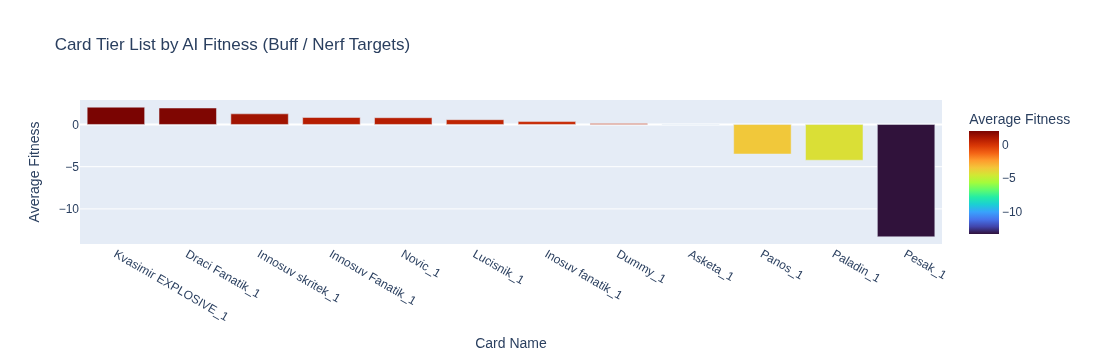

In [3]:
import plotly.express as px
from neat_ai.analysis.card_metrics import get_card_tier_list

# Load the data
tier_list = get_card_tier_list()

if not tier_list.empty:
    # Filter out cards that were barely played to avoid skewed data (flukes)
    tier_list = tier_list[tier_list['times_played'] > 5]

    # Create a bar chart
    fig = px.bar(
        tier_list,
        x='card_id',
        y='average_score',
        color='average_score',
        title='Card Tier List by AI Fitness (Buff / Nerf Targets)',
        labels={'average_score': 'Average Fitness', 'card_id': 'Card Name'},
        color_continuous_scale='Turbo'
    )
    fig.show()
else:
    print('No card data available yet.')


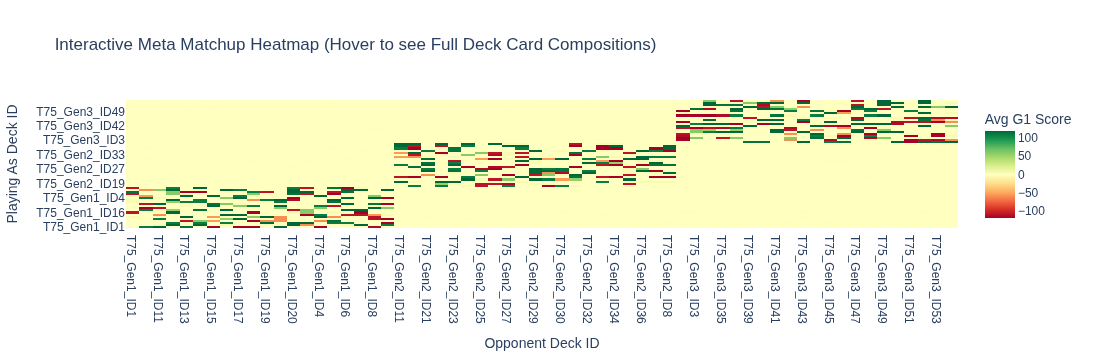

In [4]:
import plotly.graph_objects as go
import numpy as np
from neat_ai.analysis.matchups import get_matchup_matrix_with_cards

matrix, card_map = get_matchup_matrix_with_cards()

if not matrix.empty:
    # Build text matrices matching the grid layout to feed into hover metrics
    deck1_list = matrix.index.tolist()
    deck2_list = matrix.columns.tolist()

    hover_text = []
    for d1 in deck1_list:
        row_hovers = []
        for d2 in deck2_list:
            d1_cards = card_map.get(d1, 'Unknown Card List')
            d2_cards = card_map.get(d2, 'Unknown Card List')
            row_hovers.append(
                f'<b>Playing As Deck ID:</b> {d1}<br>'
                f'<b>Playing As Composition:</b> {d1_cards}<br><br>'
                f'<b>Opponent Deck ID:</b> {d2}<br>'
                f'<b>Opponent Composition:</b> {d2_cards}'
            )
        hover_text.append(row_hovers)

    fig = go.Figure(data=go.Heatmap(
        z=matrix.values,
        x=deck2_list,
        y=deck1_list,
        text=hover_text,
        hoverinfo='text+z',
        colorscale='RdYlGn',
        colorbar=dict(title='Avg G1 Score')
    ))

    fig.update_layout(
        title='Interactive Meta Matchup Heatmap (Hover to see Full Deck Card Compositions)',
        xaxis_title='Opponent Deck ID',
        yaxis_title='Playing As Deck ID'
    )
    fig.show()
else:
    print('No matchup data available yet.')


In [5]:
import plotly.graph_objects as go
from neat_ai.analysis.learning_curves import get_high_skill_decks, get_deck_trajectory

high_skill = get_high_skill_decks()

if not high_skill.empty:
    print("Top High-Skill / High-Potential Archetypes (Based on PC Match Win Rates):")
    top_curves = high_skill.head(3).copy().reset_index(drop=True)
    top_curves['rank'] = top_curves.index + 1
    top_curves['label'] = top_curves['rank'].astype(str)
    display(top_curves[['rank', 'composition', 'learning_slope', 'fitness_delta', 'gens_active']])

    palette = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd']
    dashes = ['solid', 'dash', 'dot', 'dashdot', 'longdash']
    symbols = ['circle', 'square', 'diamond', 'x', 'triangle-up']
    fig = go.Figure()

    for row_index, row in top_curves.iterrows():
        deck_trajectory = get_deck_trajectory(row['signature']).copy()
        if deck_trajectory.empty:
            continue
        deck_trajectory['label'] = row['label']
        deck_trajectory['deck_composition'] = row['composition']

        fig.add_trace(go.Scatter(
            x=deck_trajectory['gen'],
            y=deck_trajectory['score'],
            mode='lines+markers',
            name=row['label'],
            line={'color': palette[row_index % len(palette)], 'dash': dashes[row_index % len(dashes)], 'width': 4},
            marker={'color': palette[row_index % len(palette)], 'symbol': symbols[row_index % len(symbols)], 'size': 10},
            customdata=deck_trajectory[['deck_composition']],
            hovertemplate=(
                'Line %{fullData.name}<br>'
                'Generation: %{x}<br>'
                'Avg match score: %{y:.2f}<br>'
                'Composition: %{customdata[0]}<extra></extra>'
            ),
        ))

    fig.update_layout(
        title='Match Win-Rate Trajectory (Learning Curve)<br><sup>See numbered table above for archetype identities</sup>',
        xaxis_title='Inner Evaluator Generation',
        yaxis_title='Avg Match Score / Win Rate',
        legend_title='Line',
    )
    fig.show()
else:
    print("Not enough generational match data to evaluate curves yet. Run another generation.")

Not enough generational match data to evaluate curves yet. Run another generation.


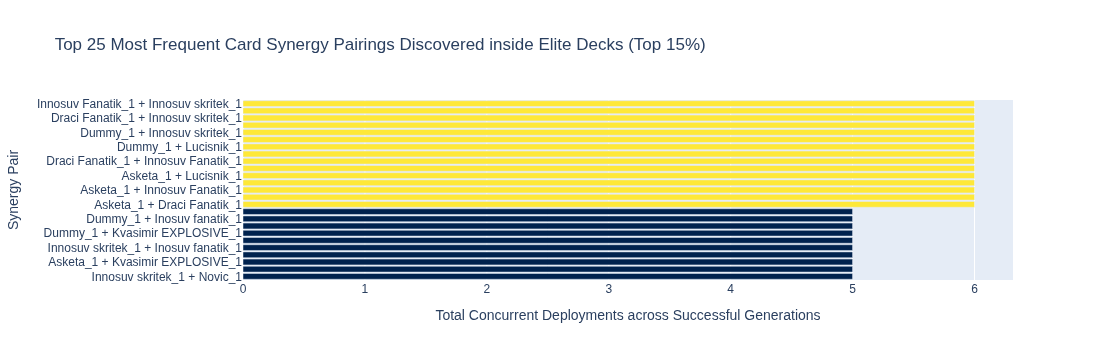

In [6]:
import plotly.express as px
from neat_ai.analysis.synergies import get_card_synergies

synergies = get_card_synergies(percentile=0.85)

if not synergies.empty:
    top_combos = synergies.head(25).copy()
    
    # Create an explicit human-readable pairing descriptor label for the axis
    top_combos['Card Combo Pairing'] = top_combos['card_A'] + " + " + top_combos['card_B']

    fig = px.bar(
        top_combos,
        x='co_occurrences',
        y='Card Combo Pairing',
        color='co_occurrences',
        orientation='h',
        title="Top 25 Most Frequent Card Synergy Pairings Discovered inside Elite Decks (Top 15%)",
        labels={'co_occurrences': 'Total Concurrent Deployments across Successful Generations', 'Card Combo Pairing': 'Synergy Pair'},
        color_continuous_scale="Cividis"
    )
    
    # Force sorting layout hierarchy
    fig.update_layout(yaxis={'categoryorder':'total ascending'}, coloraxis_showscale=False)
    fig.show()
else:
    print("No synergy metrics compiled yet. Ensure elite threshold parameters match active database score counts.")